# Embeddingi fastText + XGBoost (spam w klasie pozytywnej)

Wariant `spam_1`: ogólny klasyfikator niechcianych wiadomości, więc phishing i spam należą do klasy pozytywnej (etykieta `label_spam_1`).

- **Cechy:** 300-wymiarowy embedding dokumentu z modelu `cc.en.300.bin`, czyli średnia znormalizowanych wektorów słów
  (`get_sentence_vector`). Model jest wstępnie wytrenowany i nie widzi etykiet, więc embeddingi liczone są raz dla wszystkich
  wiadomości. Tokeny maskowania, np. `[URL]`, są spoza słownika i dostają wektor z n-gramów znakowych.
- **Dobór hiperparametrów:** grid z k-fold CV na zbiorze treningowym. Foldy są rozłączne względem klastrów, a kryterium to AUCPR
  ważone odwrotnością rozmiaru klastra. Liczba drzew jest dobierana wczesnym zatrzymaniem.
- **Podział:** 60% train, 30% val, 10% test na poziomie klastrów, taki sam we wszystkich eksperymentach.
- **Próg:** na zbiorze walidacyjnym, największy recall przy FPR ważonym klastrami nie większym niż 1%.
- **Ocena:** zbiór testowy ID i cały korpus OOD, a także każde źródło osobno.

In [ ]:
import itertools
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, OOD_SOURCES, TARGET_FPR, cluster_folds, cluster_weights, corpus_metrics, fasttext_embeddings, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)

EXPERIMENT = "fasttext_xgb_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

N_FOLDS = 3
MAX_DEPTHS = (4, 6, 8)
LEARNING_RATES = (0.05, 0.1)
MAX_ROUNDS = 5000
EARLY_STOPPING_ROUNDS = 100
SEED = 42


def xgb_params(max_depth, learning_rate):
    return {
        "objective": "binary:logistic", "tree_method": "hist", "device": "cuda",
        "max_depth": max_depth, "learning_rate": learning_rate, "seed": SEED,
    }

## Dane i podział

In [2]:
in_domain, out_of_domain = load_corpora()
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})
start = time.perf_counter()
id_embeddings, ood_embeddings = fasttext_embeddings(in_domain.text, out_of_domain.text)
embedding_seconds = time.perf_counter() - start
position = pd.Series(np.arange(len(in_domain)), index=in_domain.index)


def embed(frame):
    return ood_embeddings if frame is out_of_domain else id_embeddings[position[frame.index].to_numpy()]


print(f"Embeddingi: {id_embeddings.shape} ID, {ood_embeddings.shape} OOD, {embedding_seconds:.0f} s")

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


Embeddingi: (134469, 300) ID, (6124, 300) OOD, 55 s


## Grid z k-fold CV

Liczba drzew nie jest częścią siatki, tylko jest dobierana wczesnym zatrzymaniem (early stopping). W każdym foldzie model jest
uczony do `MAX_ROUNDS` drzew i zatrzymywany, gdy AUCPR ważone klastrami na części holdout nie rośnie przez `EARLY_STOPPING_ROUNDS`
kolejnych drzew. Wynik foldu to AUCPR dla najlepszej liczby drzew, a model końcowy dostaje średnią z tych liczb po foldach.

In [3]:
cv_rows = []
cv_start = time.perf_counter()
for fold, (fit_index, holdout_index) in enumerate(cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)):
    fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
    assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
    holdout_weights = cluster_weights(holdout_frame.cluster)
    dtrain = xgb.DMatrix(embed(fit_frame), label=fit_frame[LABEL].to_numpy())
    dholdout = xgb.DMatrix(embed(holdout_frame), label=holdout_frame[LABEL].to_numpy(), weight=holdout_weights)
    for max_depth, learning_rate in itertools.product(MAX_DEPTHS, LEARNING_RATES):
        start = time.perf_counter()
        booster = xgb.train(
            xgb_params(max_depth, learning_rate) | {"eval_metric": "aucpr"}, dtrain, num_boost_round=MAX_ROUNDS,
            evals=[(dholdout, "holdout")], early_stopping_rounds=EARLY_STOPPING_ROUNDS, verbose_eval=False,
        )
        n_estimators = booster.best_iteration + 1
        scores = booster.predict(dholdout, iteration_range=(0, n_estimators))
        cv_rows.append({
            "fold": fold, "max_depth": max_depth, "learning_rate": learning_rate, "n_estimators": n_estimators,
            "aucpr_ważone": average_precision_score(holdout_frame[LABEL], scores, sample_weight=holdout_weights),
            "aucpr": average_precision_score(holdout_frame[LABEL], scores),
        })
        print(f"fold {fold}, depth {max_depth}, lr {learning_rate}: {n_estimators} drzew, {time.perf_counter() - start:.0f} s", flush=True)
        del booster
    del dtrain, dholdout
cv_seconds = time.perf_counter() - cv_start

cv_folds = pd.DataFrame(cv_rows)
cv_folds.to_csv(TABLES / "cv_folds.csv", index=False)
GRID_COLUMNS = ["max_depth", "learning_rate"]
cv_results = (
    cv_folds.groupby(GRID_COLUMNS)[["aucpr_ważone", "aucpr", "n_estimators"]].agg(["mean", "std"])
    .sort_values(("aucpr_ważone", "mean"), ascending=False)
)
cv_results.columns = [f"{metric}_{statistic}" for metric, statistic in cv_results.columns]
cv_results = cv_results.reset_index()
cv_results.to_csv(TABLES / "cv_results.csv", index=False)
best = cv_results.iloc[0]
print(f"Czas grida: {cv_seconds / 60:.1f} min")
display(cv_results.head(10))

fold 0, depth 4, lr 0.05: 4999 drzew, 15 s


fold 0, depth 4, lr 0.1: 2193 drzew, 7 s


fold 0, depth 6, lr 0.05: 4991 drzew, 21 s


fold 0, depth 6, lr 0.1: 1717 drzew, 8 s


fold 0, depth 8, lr 0.05: 4996 drzew, 31 s


fold 0, depth 8, lr 0.1: 2949 drzew, 17 s


... (10 outputs left out)

fold 2, depth 8, lr 0.05: 1928 drzew, 17 s


fold 2, depth 8, lr 0.1: 1684 drzew, 11 s


Czas grida: 4.0 min


,max_depth,learning_rate,aucpr_ważone_mean,aucpr_ważone_std,aucpr_mean,aucpr_std,n_estimators_mean,n_estimators_std
0,6,0.0500,0.9894,0.0011,0.9917,0.0028,2939.3333,1780.0445
1,4,0.0500,0.9893,0.0009,0.9918,0.0024,4341.3333,672.4584
2,6,0.1000,0.9892,0.0010,0.9918,0.0021,1675.3333,380.2162
3,4,0.1000,0.9891,0.0010,0.9917,0.0022,2196.0000,527.5064
4,8,0.0500,0.9890,0.0013,0.9915,0.0023,2988.6667,1739.3359
5,8,0.1000,0.9888,0.0012,0.9916,0.0023,1925.6667,926.4493


## Uczenie modelu końcowego

Model z najlepszymi hiperparametrami jest uczony na całym zbiorze treningowym.

In [4]:
best_params = {
    "max_depth": int(best.max_depth),
    "learning_rate": float(best.learning_rate), "n_estimators": int(round(best.n_estimators_mean)),
}
start = time.perf_counter()
booster = xgb.train(
    xgb_params(best_params["max_depth"], best_params["learning_rate"]),
    xgb.DMatrix(embed(train), label=train[LABEL].to_numpy()),
    num_boost_round=best_params["n_estimators"],
)
training_seconds = time.perf_counter() - start
print(best_params, f"czas uczenia: {training_seconds:.0f} s")


def score(frame):
    return booster.predict(xgb.DMatrix(embed(frame)))

{'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 2939} czas uczenia: 16 s


## Dobór progu na zbiorze walidacyjnym

In [5]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params,
    "aucpr_ważone_cv": best["aucpr_ważone_mean"], "czas_embeddingów_s": embedding_seconds, "czas_grida_s": cv_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,max_depth,learning_rate,n_estimators,aucpr_ważone_cv,czas_embeddingów_s,czas_grida_s,czas_uczenia_s
0,0.0100,0.9583,0.0100,0.0179,0.9302,6,0.0500,2939,0.9894,55.0914,237.6046,16.3184


## Metryki dla ID i OOD

In [6]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,6232.0000,0.9448,0.9004,0.9396,0.9825,0.9928,0.9915,0.0146
OOD,6124.0000,4987.0000,0.2631,0.1077,0.1922,0.8950,0.7094,0.8959,0.0554


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [7]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.8758,0.8758,0.9338,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.9731,0.9731,0.9864,1.0000,NaN,NaN,NaN
trec05,5386.0000,2188.0000,0.9493,0.8967,0.9350,0.9766,0.9918,0.9886,0.0147
trec06,1582.0000,361.0000,0.9652,0.9030,0.9222,0.9422,0.9933,0.9775,0.0164
trec07,4849.0000,2430.0000,0.9443,0.9025,0.9420,0.9852,0.9937,0.9923,0.0136
ferb,5601.0000,4707.0000,0.2239,0.0778,0.1441,0.9839,0.7512,0.9357,0.0067
kd10000,60.0000,55.0000,0.4667,0.4182,0.5897,1.0000,1.0000,1.0000,0.0000
nebulon,145.0000,69.0000,0.6483,0.3768,0.5049,0.7647,0.7626,0.7367,0.1053
zeroday,318.0000,156.0000,0.7390,0.7821,0.7462,0.7135,0.8470,0.8727,0.3025


## Macierze pomyłek i krzywe

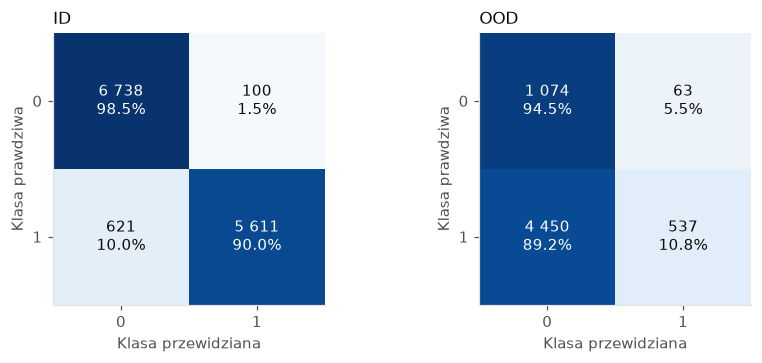

,przewidziane 0,przewidziane 1
prawdziwe 0,6738,100
prawdziwe 1,621,5611


,przewidziane 0,przewidziane 1
prawdziwe 0,1074,63
prawdziwe 1,4450,537


In [8]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

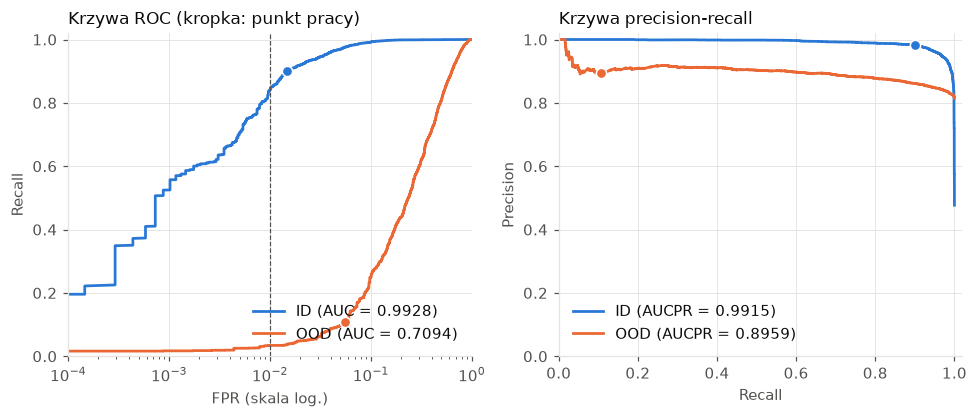

In [9]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")